# Sprawdzenie czy się wszystko zainstalowało

In [1]:
import geopandas as gpd
import rasterio
import shapely

print("geopandas", gpd.__version__)
print("rasterio ", rasterio.__version__, "| GDAL", rasterio.__gdal_version__)
print("shapely  ", shapely.__version__)

geopandas 1.2.0
rasterio  1.4.4 | GDAL 3.12.4
shapely   2.1.2


# Część A: GeoPandas

## A1. Geometria i GeoDataFrame od zera

In [2]:
from shapely.geometry import Point, Polygon

rynek = Point(17.9226, 50.6681)          # (x, y) = (longitude, latitude)
square = Polygon([(17.92, 50.66), (17.93, 50.66), (17.93, 50.67), (17.92, 50.67)])

print(rynek)
print(square.area)                       # in "units of the coordinates" - here: square degrees!
print(square.contains(rynek))

POINT (17.9226 50.6681)
0.00010000000000003127
True


In [3]:
import geopandas as gpd

places = gpd.GeoDataFrame(
    {"name": ["Rynek", "Square"]},
    geometry=[rynek, square],
    crs="EPSG:4326",                     # WGS 84 - longitude/latitude in degrees
)

print(type(places))
print(places.crs)
print(places.geom_type)



<class 'geopandas.geodataframe.GeoDataFrame'>
EPSG:4326
0      Point
1    Polygon
dtype: str


## A2. Wczytanie surowych danych

In [4]:
import pandas as pd

raw = pd.read_csv("dane/pm25_sensors.csv", parse_dates=["measured_at"])
print(raw.shape)
raw.head(10)

(145, 5)


,sensor_id,lat,lon,pm25,measured_at
0,PM-042,50.675603,17.906425,23.5,2026-10-01 08:36:00
1,PM-106,50.632283,17.919674,12.4,2026-10-01 08:22:00
2,PM-130,50.635608,18.020378,19.4,2026-10-01 08:24:00
3,PM-006,50.674051,NaN,25.7,2026-10-01 08:03:00
4,PM-025,50.676438,17.938766,16.8,2026-10-01 08:13:00
5,PM-137,17.873510,50.677587,14.4,2026-10-01 08:06:00
6,PM-036,50.666829,17.940071,23.7,2026-10-01 08:23:00
7,PM-100,50.694328,17.802222,12.5,2026-10-01 08:56:00
8,PM-092,50.684393,17.794548,9.3,2026-10-01 08:09:00
9,PM-087,50.650288,17.940259,-999.0,2026-10-01 08:56:00


In [5]:
print(raw[["lat", "lon", "pm25"]].describe())
print(raw.isna().sum())
print(raw.duplicated().sum())

              lat         lon        pm25
count  142.000000  141.000000  145.000000
mean    49.980869   18.613736   -8.995172
std      4.727557    4.743171  167.401474
min     17.873510   17.785622 -999.000000
25%     50.652463   17.897319   14.500000
50%     50.669682   17.918011   19.100000
75%     50.686753   17.940870   22.500000
max     50.767895   50.677587   35.300000
sensor_id      0
lat            3
lon            4
pm25           0
measured_at    0
dtype: int64
5


## A3. Czyszczenie danych

In [6]:
df = raw.copy()
report = {"input rows": len(df)}

# 1. Duplicates - the same message sent twice
df = df.drop_duplicates()
report["after drop_duplicates"] = len(df)

# 2. Rows without coordinates cannot be placed on a map
df = df.dropna(subset=["lat", "lon"])
report["after dropna"] = len(df)

# 3. Swapped coordinates: in Poland lat is 49-55 and lon is 14-24
swapped = df["lat"].between(14, 24.5) & df["lon"].between(49, 55)
df.loc[swapped, ["lat", "lon"]] = df.loc[swapped, ["lon", "lat"]].to_numpy()
report["swapped rows fixed"] = int(swapped.sum())

# 4. -999 is the sensor's error code, not a measurement
df = df[df["pm25"] >= 0].reset_index(drop=True)
report["clean rows"] = len(df)

report

{'input rows': 145,
 'after drop_duplicates': 140,
 'after dropna': 134,
 'swapped rows fixed': 3,
 'clean rows': 130}

In [7]:
df[["lat", "lon", "pm25"]].describe().round(2)

,lat,lon,pm25
count,130.00,130.00,130.00
mean,50.67,17.92,18.86
std,0.03,0.04,5.19
min,50.62,17.79,9.20
25%,50.65,17.90,14.65
50%,50.67,17.92,19.00
75%,50.69,17.94,22.22
max,50.77,18.02,35.30


## A4. Z tabeli do GeoDataFrame

In [8]:
sensors = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["lon"], df["lat"]),   # x = lon, y = lat!
    crs="EPSG:4326",
)
print(sensors.head())
print(sensors.geom_type.unique())
print(sensors.crs)
print(sensors.total_bounds)              # [minx, miny, maxx, maxy]

  sensor_id        lat        lon  pm25         measured_at  \
0    PM-042  50.675603  17.906425  23.5 2026-10-01 08:36:00   
1    PM-106  50.632283  17.919674  12.4 2026-10-01 08:22:00   
2    PM-130  50.635608  18.020378  19.4 2026-10-01 08:24:00   
3    PM-025  50.676438  17.938766  16.8 2026-10-01 08:13:00   
4    PM-137  50.677587  17.873510  14.4 2026-10-01 08:06:00   

                    geometry  
0   POINT (17.90642 50.6756)  
1  POINT (17.91967 50.63228)  
2  POINT (18.02038 50.63561)  
3  POINT (17.93877 50.67644)  
4  POINT (17.87351 50.67759)  
<ArrowStringArray>
['Point']
Length: 1, dtype: str
EPSG:4326
[17.785622 50.616593 18.020378 50.767895]


In [9]:
sensors.explore(column="pm25", cmap="Oranges", marker_kwds={"radius": 6})

In [10]:
sensors2 = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["lat"], df["lon"]),   # x = lon, y = lat!
    crs="EPSG:4326",
)
sensors2.explore(column="pm25", cmap="Oranges", marker_kwds={"radius": 6})

## A5. Układy współrzędnych

In [11]:
a, b = sensors.geometry.iloc[0], sensors.geometry.iloc[1]
a.distance(b)

sensors_m = sensors.to_crs("EPSG:2180")
sensors_m.geometry.iloc[0].distance(sensors_m.geometry.iloc[1])

sensors_m.head(3)[["sensor_id", "geometry"]]


,sensor_id,geometry
0,PM-042,POINT (422754.546 312637.211)
1,PM-106,POINT (423620.153 307808.028)
2,PM-130,POINT (430744.745 308078.679)


In [12]:
from pyproj import Geod

gdansk, zakopane = (18.6466, 54.3520), (19.9496, 49.2992)
pts = gpd.GeoSeries.from_xy([gdansk[0], zakopane[0]], [gdansk[1], zakopane[1]], crs="EPSG:4326")

_, _, true_m = Geod(ellps="WGS84").inv(*gdansk, *zakopane)
print(f"geodesic : {true_m / 1000:8.1f} km")

for crs in ["EPSG:3857", "EPSG:2180"]:
    p = pts.to_crs(crs)
    d = p.iloc[0].distance(p.iloc[1])
    print(f"{crs}: {d / 1000:8.1f} km   error {100 * (d / true_m - 1):+.2f} %")

geodesic :    569.3 km
EPSG:3857:    922.8 km   error +62.09 %
EPSG:2180:    568.9 km   error -0.07 %


## A6. Poligony: dzielnice Opola

29 EPSG:4326
City area: 148.8 km²


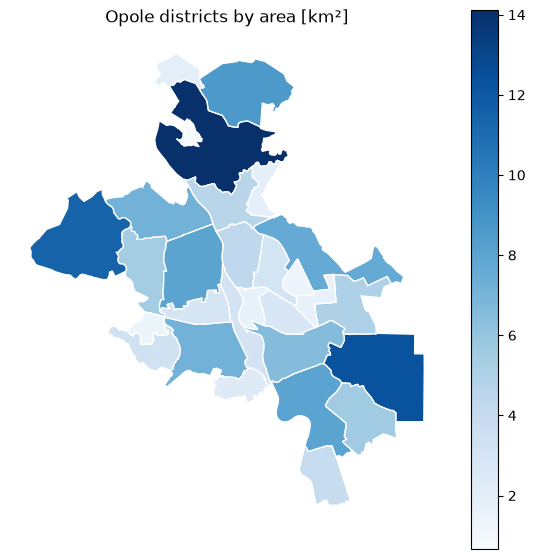

In [13]:
districts = gpd.read_file("dane/opole_districts.geojson")
print(len(districts), districts.crs)
districts.head()

districts = districts.to_crs("EPSG:2180")
districts["area_km2"] = districts.area / 1e6        # m² -> km²

print(f"City area: {districts['area_km2'].sum():.1f} km²")
districts.sort_values("area_km2", ascending=False).head()

import matplotlib.pyplot as plt

ax = districts.plot(column="area_km2", cmap="Blues", legend=True,
                    edgecolor="white", figsize=(7, 7))
ax.set_title("Opole districts by area [km²]")
ax.set_axis_off()
plt.show()

## A7. Złączenie przestrzenne

In [14]:
joined = gpd.sjoin(
    sensors_m,                                   # left: points
    districts[["name", "geometry"]],             # right: polygons (only the columns we need)
    how="left",
    predicate="within",                          # point lies within polygon
)
print(len(joined), joined["name"].isna().sum())
joined[["sensor_id", "pm25", "name"]].head()

stats = (joined.groupby("name")
               .agg(pm25_mean=("pm25", "mean"), sensor_count=("pm25", "size"))
               .round(1))

summary = districts.merge(stats, on="name", how="left")
summary.sort_values("pm25_mean", ascending=False).head()

reliable = summary[summary["sensor_count"] >= 3]
reliable.nlargest(3, "pm25_mean")[["name", "pm25_mean", "sensor_count"]]

summary.explore(column="pm25_mean", cmap="Oranges", scheme="quantiles", k=5,
                legend_kwds={"caption": "mean PM2.5 [µg/m³]"},
                missing_kwds={"color": "lightgray", "label": "no sensors"})

130 0


## A8. Bufory

In [15]:
schools = gpd.read_file("dane/opole_schools.geojson").to_crs("EPSG:2180")

buffers = schools.copy()
buffers["geometry"] = schools.buffer(500)          # metres, because EPSG:2180
buffers.head(3)

near_schools = gpd.sjoin(sensors_m, buffers[["name", "geometry"]], predicate="within")

print("schools:", len(schools))
print("schools with a sensor within 500 m:", near_schools["name"].nunique())
print(f"mean PM2.5 near schools: {near_schools['pm25'].mean():.1f} µg/m³")

city = districts.union_all()
coverage = buffers.union_all().intersection(city).area / city.area
print(f"{coverage:.1%} of the city")

m = districts.explore(color="gray", style_kwds={"fillOpacity": 0.05}, name="districts")
buffers.explore(m=m, color="orange", name="500 m buffers")
sensors_m.explore(m=m, color="black", marker_kwds={"radius": 3}, name="sensors")
m


schools: 19
schools with a sensor within 500 m: 11
mean PM2.5 near schools: 22.3 µg/m³
9.5% of the city


## A9. Zapis wyników

In [16]:
from pathlib import Path

out = Path("wyniki")
out.mkdir(exist_ok=True)

# GeoPackage: many layers in one file, any CRS - the default choice
summary.to_file(out / "pm25.gpkg", layer="districts", driver="GPKG")
sensors_m.to_file(out / "pm25.gpkg", layer="sensors", driver="GPKG")

# GeoJSON: for web applications - always save it in EPSG:4326
summary.to_crs("EPSG:4326").to_file(out / "pm25_districts.geojson", driver="GeoJSON")

gpd.list_layers(out / "pm25.gpkg")

check = gpd.read_file(out / "pm25.gpkg", layer="districts")
print(len(check), check.crs)


29 EPSG:2180
